<div style="background:#C25E00;color:white;padding:18px 22px;border-radius:10px;border-bottom:5px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/algoprofessor-ai-scientist/main/assets/logo_transparent.png" alt="Algo Professor" style="float:right;height:74px;background:white;border-radius:8px;padding:4px 8px">
<div style="font-size:13px;letter-spacing:2px;color:#F6EBC4">ALGOPROFESSOR · AI SCIENTIST HANDS-ON · SUNDAY 5</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Agentic AI Systems</div>
<div style="font-size:15px;margin-top:6px">Hours 21–25 · 2 h hands-on teaching + 3 h real-time project work · GitHub submission by 18:00</div>
</div>

| Hour | Mode | Focus | Dataset |
|---|---|---|---|
| 21 | TEACH | Tool use, function calling, the ReAct loop, MCP tool manifests | Multi-hop questions over the course syllabus |
| 22 | TEACH | Multi-agent graph: planner → executor → critic, memory, guardrails | GSM8K (1,319 test problems) |
| 23 | BUILD | ScholarAgent: search papers, rank, write a cited summary | arXiv API (live in class) / offline paper index |
| 24 | BUILD | Sandboxed code-execution agent that reproduces a baseline | UCI Adult |
| 25 | BUILD | Agent evaluation & observability: traces, cost, failure taxonomy, human approval | 12-task agent test suite |

> **About the "LLM" in this notebook.** To run anywhere without an API key, the agent's decisions come from a small
> rule-based policy (`MockLLM`). Every other part — tool schemas, the ReAct loop, the graph, guardrails, sandbox,
> tracing and evaluation — is the real thing. Set `ANTHROPIC_API_KEY` or `OPENAI_API_KEY` in class and swap in `RealLLM`.

In [1]:
# ---------- Setup (run once) ----------
import os, pathlib, urllib.request, warnings, time, json, random
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Data cache lives at the repository root (data/ is git-ignored); figures go next to the notes.
DATA = pathlib.Path(os.environ.get("AP_DATA", "../../data")); DATA.mkdir(parents=True, exist_ok=True)
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)

def fetch(url, name):
    """Download a file once into the shared data cache and return its path."""
    p = DATA / name
    if not p.exists():
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(url, p)
    return p

# AlgoProfessor colour palette
NAVY, GOLD, GREEN, PURPLE = "#0B1F3A", "#C9A227", "#1E7B5A", "#6A3D9A"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"],
                     "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "xtick.color": NAVY, "ytick.color": NAVY,
                     "axes.titleweight": "bold", "axes.titlecolor": NAVY, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=[NAVY, GOLD, GREEN, PURPLE, "#A4243B", "#C25E00"])})
print("Setup complete. Data cache:", DATA.resolve())

Setup complete. Data cache: /home/claude/build/data


In [2]:
import re, ast, operator, subprocess, sys, tempfile, textwrap, uuid, collections, math
from dataclasses import dataclass, field
from pypdf import PdfReader
from rank_bm25 import BM25Okapi

---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 21 — Tool use, function calling and the ReAct loop

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Multi-hop questions over the course syllabus PDF</span>
**Skills:** <span style="color:#6A3D9A">Function calling, ReAct prompting, MCP tools</span>

**Function calling:** the model never runs code itself. It outputs a structured request —
`{"tool": "search", "args": {"query": "..."}}` — your program runs the tool and feeds back the result.
**ReAct** = *Reason → Act (call a tool) → Observe → repeat*, until the model gives a final answer.

In [3]:
# --- Tool 1: search the syllabus PDF (BM25 over page-level passages) ---
SYL = pathlib.Path("../../syllabus/AlgoProfessor_AI_Scientist_Syllabus.pdf")
if not SYL.exists(): SYL = fetch("https://raw.githubusercontent.com/drssnaiml1-cell/algoprofessor-ai-scientist/main/syllabus/AlgoProfessor_AI_Scientist_Syllabus.pdf", "AlgoProfessor_AI_Scientist_Syllabus.pdf")   # Colab fallback
pages = [re.sub(r"\s+", " ", p.extract_text() or "") for p in PdfReader(SYL).pages]
passages = []
for pg, t in enumerate(pages, 1):
    w = t.split()
    for i in range(0, len(w), 40): passages.append({"page": pg, "text": " ".join(w[i:i + 60])})
tok = lambda s: re.findall(r"[a-z0-9\-]+", s.lower())
bm = BM25Okapi([tok(p["text"]) for p in passages])

def search(query: str, k: int = 2) -> list:
    scores = bm.get_scores(tok(query)); top = np.argsort(-scores)[:k]
    return [{"page": passages[i]["page"], "text": passages[i]["text"]} for i in top]

# --- Tool 2: structured lookup of one course hour (a 'database' tool beats free-text search for exact facts) ---
full_text = " ".join(pages)
def lookup_hour(hour: int) -> dict:
    m = re.search(rf"(?<![\d–-]){hour} (TEACH|BUILD) (.*?)(?= \d+ (?:TEACH|BUILD) |Deliverable|$)", full_text)
    return {"hour": hour, "mode": m.group(1), "row": m.group(2)[:260]} if m else {"hour": hour, "row": None}

# --- Tool 3: a SAFE calculator (parses arithmetic only — no eval of arbitrary code) ---
OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.Pow: operator.pow, ast.USub: operator.neg, ast.UAdd: operator.pos, ast.Mod: operator.mod, ast.FloorDiv: operator.floordiv}
def calculator(expression: str) -> float:
    def ev(n):
        if isinstance(n, ast.Constant) and isinstance(n.value, (int, float)): return n.value
        if isinstance(n, ast.BinOp) and type(n.op) in OPS: return OPS[type(n.op)](ev(n.left), ev(n.right))
        if isinstance(n, ast.UnaryOp) and type(n.op) in OPS: return OPS[type(n.op)](ev(n.operand))
        raise ValueError(f"disallowed expression element: {type(n).__name__}")
    return ev(ast.parse(expression.replace(",", ""), mode="eval").body)

TOOLS = {"lookup_hour": {"fn": lookup_hour, "description": "Return the syllabus row (topic, dataset, skills) for course hour 1-30.",
                         "parameters": {"type": "object", "properties": {"hour": {"type": "integer"}}, "required": ["hour"]}},
         "search": {"fn": search, "description": "Search the course syllabus. Returns passages with page numbers.",
                    "parameters": {"type": "object", "properties": {"query": {"type": "string"}, "k": {"type": "integer"}}, "required": ["query"]}},
         "calculator": {"fn": calculator, "description": "Evaluate an arithmetic expression exactly.",
                        "parameters": {"type": "object", "properties": {"expression": {"type": "string"}}, "required": ["expression"]}}}
print(calculator("50000 / 83.5"), "|", search("LeafDoctor deliverable", 1)[0]["page"], "|", lookup_hour(6)["row"][:80])
try: calculator("__import__('os').system('rm -rf /')")
except ValueError as e: print("guardrail blocked:", e)

598.8023952095808 | 5 | Tensors, autograd, the training loop from scratch, MLPs, optimisers (SGD, Adam),
guardrail blocked: disallowed expression element: Call


In [4]:
# The same tool registry, exported as an MCP-style tool manifest (what an MCP server advertises to any client)
manifest = {"tools": [{"name": n, "description": t["description"], "inputSchema": t["parameters"]} for n, t in TOOLS.items()]}
print(json.dumps(manifest, indent=1)[:600])

{
 "tools": [
  {
   "name": "lookup_hour",
   "description": "Return the syllabus row (topic, dataset, skills) for course hour 1-30.",
   "inputSchema": {
    "type": "object",
    "properties": {
     "hour": {
      "type": "integer"
     }
    },
    "required": [
     "hour"
    ]
   }
  },
  {
   "name": "search",
   "description": "Search the course syllabus. Returns passages with page numbers.",
   "inputSchema": {
    "type": "object",
    "properties": {
     "query": {
      "type": "string"
     },
     "k": {
      "type": "integer"
     }
    },
    "required": [
     "query"
   


With the official SDK (`pip install mcp`) the server is a few lines — any MCP client (Claude Desktop, IDEs, your agents)
can then discover and call these tools:

```python
from mcp.server.fastmcp import FastMCP
mcp = FastMCP("algoprofessor-course")
@mcp.tool()
def search_syllabus(query: str) -> list: return search(query)
mcp.run()
```

In [5]:
@dataclass
class Step: thought: str; tool: str = None; args: dict = None; observation: object = None

STOPW = set("the a an of to in on for and or is are was what which who when how does do did be by with at as it this that from".split())

class MockLLM:
    """Rule-based stand-in for an LLM policy. It decides the next action from the question and the observations so far."""
    def next(self, question, steps):
        q = question.lower()
        m = re.search(r"which sunday.*?project (?:is )?called (\w+).*?hour (\d)", q)
        if m:                                                     # 2-hop: find the Sunday of a project, then that Sunday's hour
            proj, hr = m.group(1), int(m.group(2))
            if not steps: return Step(f"Find which Sunday builds {proj}.", "search", {"query": f"Deliverable {proj}", "k": 1})
            if len(steps) == 1:
                sunday = int(re.search(r"Sunday (\d)", steps[0].observation[0]["text"]).group(1))
                hour_no = (sunday - 1) * 5 + hr
                return Step(f"{proj} is Sunday {sunday}; its hour {hr} is course hour {hour_no}.", "lookup_hour", {"hour": hour_no})
            return Step("I have the hour's row; answer from it.", None, None, steps[1].observation["row"])
        if "convert" in q or re.search(r"\d+\s*(usd|us\$|dollars?)", q):
            if not steps: return Step("Look up the India fee first.", "search", {"query": "Programme fee INR India", "k": 1})
            if len(steps) == 1:
                inr = float(re.search(r"INR ([\d,]+)", steps[0].observation[0]["text"]).group(1).replace(",", ""))
                rate = float(re.search(r"([\d.]+) (?:inr|rupees) per", q).group(1))
                return Step(f"Fee is INR {inr:,.0f}; divide by the given rate.", "calculator", {"expression": f"{inr}/{rate}"})
            return Step("Done.", None, None, f"About US$ {steps[-1].observation:,.0f}")
        if not steps: return Step("Search the syllabus.", "search", {"query": question, "k": 3})
        qs = set(tok(question)) - STOPW; best, score = "", -1          # pick the 20-word window sharing most question words
        for p in steps[0].observation:
            w = p["text"].split()
            for i in range(0, max(1, len(w) - 19), 3):
                span = " ".join(w[i:i + 20]); sc = len(qs & set(tok(span)))
                if sc > score: best, score = span, sc
        return Step("Answer from the best window of the top passages.", None, None, best)

def react(question, llm=MockLLM(), max_steps=5, trace=None):
    steps = []
    for _ in range(max_steps):
        st = llm.next(question, steps)
        if st.tool is None: return st.observation, steps
        t0 = time.perf_counter(); st.observation = TOOLS[st.tool]["fn"](**st.args)
        if trace is not None: trace.append({"tool": st.tool, "args": st.args, "ms": round((time.perf_counter() - t0) * 1000, 2)})
        steps.append(st)
    return "Stopped: step limit reached.", steps

ans, steps = react("Which Sunday has the project called LeafDoctor, and which dataset does it use in hour 1?")
for i, s in enumerate(steps, 1):
    obs = f"page {s.observation[0]['page']}" if isinstance(s.observation, list) else str(s.observation)[:110]
    print(f"Step {i} | THOUGHT: {s.thought}\n        | ACT: {s.tool}({s.args}) -> {obs}")
print("FINAL:", ans)

Step 1 | THOUGHT: Find which Sunday builds leafdoctor.
        | ACT: search({'query': 'Deliverable leafdoctor', 'k': 1}) -> page 5
Step 2 | THOUGHT: leafdoctor is Sunday 2; its hour 1 is course hour 6.
        | ACT: lookup_hour({'hour': 6}) -> {'hour': 6, 'mode': 'TEACH', 'row': 'Tensors, autograd, the training loop from scratch, MLPs, optimisers (SGD,
FINAL: Tensors, autograd, the training loop from scratch, MLPs, optimisers (SGD, Adam), regularisation. Fashion-MNIST (70,000 images, 10 classes) PyTorch core, autograd, custom training loops, debugging loss curves


In [6]:
ans, steps = react("Convert the India programme fee to dollars at 83.5 INR per USD")
for s in steps: print("THOUGHT:", s.thought, "| ACT:", s.tool, s.args, "| OBS:", str(s.observation)[:70])
print("FINAL:", ans)

THOUGHT: Look up the India fee first. | ACT: search {'query': 'Programme fee INR India', 'k': 1} | OBS: [{'page': 1, 'text': 'AI R&D Solutions Hyderabad, India MADE IN INDIA 
THOUGHT: Fee is INR 50,000; divide by the given rate. | ACT: calculator {'expression': '50000.0/83.5'} | OBS: 598.8023952095808
FINAL: About US$ 599


---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 22 — Multi-agent graph: planner → executor → critic, with memory and guardrails

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">GSM8K test set (1,319 maths word problems)</span>
**Skills:** <span style="color:#6A3D9A">LangGraph-style state machines, self-critique, agent memory, guardrails</span>

GSM8K reference solutions mark every calculation like `<<16-3-4=9>>`. Our agent team checks a reasoning trace:
the **planner** extracts the steps, the **executor** recomputes each with the calculator tool, the **critic** compares
with the final answer `#### n` and decides *accept* or *flag*. This is the self-verification loop production agents use.

In [7]:
gsm = [json.loads(l) for l in fetch("https://raw.githubusercontent.com/openai/grade-school-math/master/grade_school_math/data/test.jsonl", "gsm8k_test.jsonl").read_text().splitlines()]
print(len(gsm), "problems\n"); print(gsm[0]["question"]); print("---"); print(gsm[0]["answer"])

1319 problems

Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
---
Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.
She makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.
#### 18


In [8]:
class Graph:
    """A minimal LangGraph-style state machine: named nodes + conditional edges + shared state."""
    def __init__(self): self.nodes, self.edges = {}, {}
    def add_node(self, name, fn): self.nodes[name] = fn
    def add_edge(self, src, router): self.edges[src] = router          # router(state) -> next node name or "END"
    def run(self, state, start, max_hops=10):
        node = start
        for _ in range(max_hops):
            state = self.nodes[node](state); state["path"].append(node)
            node = self.edges[node](state)
            if node == "END": break
        return state

def planner(s):
    s["plan"] = re.findall(r"<<([^=<>]+)=([^<>]+)>>", s["trace"]); return s
def executor(s):
    s["checks"] = []
    for expr, claimed in s["plan"]:
        try: got = calculator(expr); want = calculator(claimed); ok = abs(got - want) < 1e-6 * max(1, abs(got))
        except Exception as e: got, ok = f"error: {e}", False
        s["checks"].append({"expr": expr, "claimed": claimed, "recomputed": got, "ok": ok})
    return s
def critic(s):
    final = float(s["trace"].split("####")[-1].strip().replace(",", ""))
    last = s["checks"][-1]["recomputed"] if s["checks"] else None
    s["arith_ok"] = all(c["ok"] for c in s["checks"])
    s["final_matches_last_step"] = last is not None and not isinstance(last, str) and abs(float(last) - final) < 1e-6
    s["verdict"] = "accept" if s["arith_ok"] else "flag"
    return s

g = Graph()
g.add_node("planner", planner); g.add_node("executor", executor); g.add_node("critic", critic)
g.add_edge("planner", lambda s: "executor" if s["plan"] else "END")
g.add_edge("executor", lambda s: "critic"); g.add_edge("critic", lambda s: "END")

memory = []                                              # long-term memory: every verdict is stored for later analysis
for i, item in enumerate(gsm):
    st = g.run({"id": i, "trace": item["answer"], "path": []}, "planner"); memory.append(st)

mem = pd.DataFrame([{"id": m["id"], "steps": len(m.get("plan", [])), "verdict": m.get("verdict", "no-plan"),
                     "final=last step": m.get("final_matches_last_step")} for m in memory])
print(mem.verdict.value_counts().to_string()); print("\nmean calculation steps per problem:", round(mem.steps.mean(), 2))
print("final answer equals last computed step:", round(mem["final=last step"].mean(), 3))

verdict
accept     1301
no-plan      18

mean calculation steps per problem: 3.25
final answer equals last computed step: 0.929


In [9]:
flagged = [m for m in memory if m.get("verdict") == "flag"]
print(f"{len(flagged)} traces flagged by the critic. First examples:")
for m in flagged[:4]:
    bad = [c for c in m["checks"] if not c["ok"]][0]
    print(f"  #{m['id']}: <<{bad['expr']}={bad['claimed']}>>  recomputed -> {bad['recomputed']}")

0 traces flagged by the critic. First examples:


**What the critic taught us.** Our first version flagged 6 traces — every one was *format noise* (a unary `+8`, a
fraction written as `3/4`), not a maths error. After teaching the calculator those notations, all traces with
calculations pass. Lesson: most agent "failures" in a first run are interface mismatches between tools and data;
look at flagged cases before trusting a failure rate. The ~7% of traces whose final answer is not the last computed
value are worth a look too — the last step there is often an intermediate quantity.

**Guardrails used so far:** calculator accepts arithmetic only · step limit in the ReAct loop · graph hop limit ·
every decision stored in memory for audit.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 23 — ScholarAgent: an AI research-scientist agent

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">arXiv API (live in class) / offline index of this course's key papers</span>
**Skills:** <span style="color:#6A3D9A">API tool integration, rate limits, citation tracking</span>

In [10]:
import urllib.parse, xml.etree.ElementTree as ET
# Offline fallback index: the papers behind this course's datasets and methods (titles, authors, years are real;
# 'summary' lines are our own one-sentence descriptions, not the papers' abstracts).
OFFLINE_PAPERS = [
 ("Attention Is All You Need", "Vaswani et al.", 2017, "arXiv:1706.03762", "Introduces the Transformer, built only from attention layers."),
 ("LoRA: Low-Rank Adaptation of Large Language Models", "Hu et al.", 2021, "arXiv:2106.09685", "Fine-tunes large models by training small low-rank matrices added to frozen weights."),
 ("Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks", "Lewis et al.", 2020, "arXiv:2005.11401", "Combines a retriever with a generator so answers draw on external documents."),
 ("ReAct: Synergizing Reasoning and Acting in Language Models", "Yao et al.", 2022, "arXiv:2210.03629", "Interleaves reasoning traces with tool actions in a single loop."),
 ("Training Verifiers to Solve Math Word Problems", "Cobbe et al.", 2021, "arXiv:2110.14168", "Introduces GSM8K and trains verifiers to check candidate solutions."),
 ("TruthfulQA: Measuring How Models Mimic Human Falsehoods", "Lin et al.", 2021, "arXiv:2109.07958", "A benchmark of questions where popular misconceptions lead models to false answers."),
 ("Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms", "Xiao et al.", 2017, "arXiv:1708.07747", "A harder drop-in replacement for MNIST with clothing images."),
 ("An open access repository of images on plant health to enable the development of mobile disease diagnostics", "Hughes & Salathe", 2015, "arXiv:1511.08060", "Releases the PlantVillage leaf image collection."),
 ("An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale", "Dosovitskiy et al.", 2020, "arXiv:2010.11929", "Applies a plain Transformer to sequences of image patches (ViT)."),
 ("Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization", "Selvaraju et al.", 2016, "arXiv:1610.02391", "Highlights image regions that drive a CNN's prediction using gradients."),
 ("A Unified Approach to Interpreting Model Predictions", "Lundberg & Lee", 2017, "arXiv:1705.07874", "Introduces SHAP values for explaining individual predictions."),
 ("Efficient and robust approximate nearest neighbor search using Hierarchical Navigable Small World graphs", "Malkov & Yashunin", 2016, "arXiv:1603.09320", "Introduces HNSW graphs for fast vector search."),
]

def search_papers(query, k=4, timeout=8):
    """Live arXiv API first; fall back to the offline index if the network is unavailable."""
    url = "http://export.arxiv.org/api/query?" + urllib.parse.urlencode({"search_query": f"all:{query}", "max_results": k})
    try:
        xml = urllib.request.urlopen(url, timeout=timeout).read(); ns = {"a": "http://www.w3.org/2005/Atom"}
        out = [{"title": e.find("a:title", ns).text.strip(), "authors": e.find("a:author/a:name", ns).text + " et al.",
                "year": int(e.find("a:published", ns).text[:4]), "id": e.find("a:id", ns).text, "summary": e.find("a:summary", ns).text.strip()[:200]}
               for e in ET.fromstring(xml).findall("a:entry", ns)]
        return out, "arXiv API (live)"
    except Exception as e:
        docs = [f"{t} {s}" for t, a, y, i, s in OFFLINE_PAPERS]; b = BM25Okapi([tok(d) for d in docs])
        qt = [w for w in tok(query) if w not in STOPW]; sc = b.get_scores(qt)
        top = [i for i in np.argsort(-sc)[:k] if sc[i] >= 0.5 * sc.max() > 0]        # keep only clearly relevant papers
        return [dict(zip(["title", "authors", "year", "id", "summary"], OFFLINE_PAPERS[i])) for i in top], f"offline index ({type(e).__name__})"

def scholar_agent(topic, k=4):
    papers, source = search_papers(topic, k)
    lines = [f"## Literature summary: {topic}", f"*Source: {source}; {len(papers)} papers.*", ""]
    for n, p in enumerate(papers, 1):
        lines.append(f"{n}. **{p['title']}** — {p['authors']} ({p['year']}), {p['id']}. {p['summary']} [{n}]")
    first = min(range(len(papers)), key=lambda i: papers[i]["year"]) + 1 if papers else None
    lines += ["", "**Synthesis:** " + (f"The earliest work here is [{first}] ({min(p['year'] for p in papers)}). "
              "Every claim above cites a numbered source — an agent must never write a paper it did not retrieve." if papers else "No sources found; the agent stops instead of guessing.")]
    return "\n".join(lines)

print(scholar_agent("efficient fine-tuning of large language models with low rank adaptation"))
print(); print(scholar_agent("retrieval augmented generation and reasoning with tools"))

## Literature summary: efficient fine-tuning of large language models with low rank adaptation
*Source: offline index (URLError); 1 papers.*

1. **LoRA: Low-Rank Adaptation of Large Language Models** — Hu et al. (2021), arXiv:2106.09685. Fine-tunes large models by training small low-rank matrices added to frozen weights. [1]

**Synthesis:** The earliest work here is [1] (2021). Every claim above cites a numbered source — an agent must never write a paper it did not retrieve.

## Literature summary: retrieval augmented generation and reasoning with tools
*Source: offline index (URLError); 2 papers.*

1. **ReAct: Synergizing Reasoning and Acting in Language Models** — Yao et al. (2022), arXiv:2210.03629. Interleaves reasoning traces with tool actions in a single loop. [1]
2. **Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks** — Lewis et al. (2020), arXiv:2005.11401. Combines a retriever with a generator so answers draw on external documents. [2]

**Synthesis:** The earli

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 24 — Sandboxed code-execution agent

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">UCI Adult (baseline reproduction)</span>
**Skills:** <span style="color:#6A3D9A">Docker sandboxing, permission boundaries, reproducibility</span>

In [11]:
BANNED_CALLS = {"system", "popen", "remove", "rmtree", "unlink", "exec", "eval", "__import__", "socket", "urlopen", "requests"}
def static_check(code):
    """Refuse code that touches the OS, network or dynamic execution before it ever runs."""
    for node in ast.walk(ast.parse(code)):
        if isinstance(node, ast.Attribute) and node.attr in BANNED_CALLS: return f"blocked attribute: {node.attr}"
        if isinstance(node, ast.Name) and node.id in BANNED_CALLS: return f"blocked name: {node.id}"
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            mods = [a.name for a in node.names] if isinstance(node, ast.Import) else [node.module]
            if any(m.split(".")[0] in {"os", "subprocess", "socket", "shutil", "requests", "urllib"} for m in mods): return f"blocked import: {mods}"
    return None

def run_sandboxed(code, timeout=60):
    if (why := static_check(code)): return {"ok": False, "stdout": "", "stderr": why}
    with tempfile.TemporaryDirectory() as d:
        path = pathlib.Path(d) / "job.py"; path.write_text(code)
        pre = "import resource; resource.setrlimit(resource.RLIMIT_AS, (2_000_000_000, 2_000_000_000))"
        r = subprocess.run([sys.executable, "-I", "-c", pre + f"; exec(open({str(path)!r}).read())"], cwd=d,
                           capture_output=True, text=True, timeout=timeout, env={"PATH": "/usr/bin:/bin"})
        return {"ok": r.returncode == 0, "stdout": r.stdout[-800:], "stderr": r.stderr[-400:]}

adult_path = str((DATA / "adult-all.csv").resolve()); fetch("https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv", "adult-all.csv")
job = textwrap.dedent(f'''
    import pandas as pd, numpy as np
    from sklearn.model_selection import cross_val_score
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.compose import make_column_transformer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    cols = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation","relationship","race","sex",
            "capital_gain","capital_loss","hours_per_week","native_country","income"]
    df = pd.read_csv({adult_path!r}, header=None, names=cols, na_values="?", skipinitialspace=True).fillna("Unknown")
    y = (df.pop("income") == ">50K").astype(int)
    num = ["age","education_num","capital_gain","capital_loss","hours_per_week"]; cat = ["workclass","marital_status","occupation","relationship","sex"]
    pipe = make_pipeline(make_column_transformer((StandardScaler(), num), (OneHotEncoder(handle_unknown="ignore"), cat)), LogisticRegression(max_iter=1000))
    acc = cross_val_score(pipe, df[num + cat], y, cv=5, scoring="accuracy")
    print(f"BASELINE logistic regression 5-fold accuracy: {{acc.mean():.4f}} +/- {{acc.std():.4f}}")
''')
print(run_sandboxed(job)["stdout"])
for bad in ["import os\nos.system('ls /')", "open('/etc/passwd').read()\n__import__('socket')", "x = [0] * 10**10"]:
    r = run_sandboxed(bad, timeout=20); print("UNSAFE JOB ->", "ok" if r["ok"] else "refused/failed:", (r["stderr"] or r["stdout"]).strip().splitlines()[-1][:90])

BASELINE logistic regression 5-fold accuracy: 0.8515 +/- 0.0023

UNSAFE JOB -> refused/failed: blocked import: ['os']
UNSAFE JOB -> refused/failed: blocked name: __import__
UNSAFE JOB -> refused/failed: MemoryError


**Defence in depth:** static checks catch obvious misuse, a separate process with memory and time limits contains
the rest. In production run jobs in a **container with no network** (`docker run --network none --memory 2g --cpus 1`),
or a managed sandbox. Never execute model-written code in your own process.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 25 — Agent evaluation and observability

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">12-task agent test suite (GAIA validation in class)</span>
**Skills:** <span style="color:#6A3D9A">Agent evals, tracing, cost control, human-in-the-loop</span>

In [12]:
def send_email(to, body, approved_by_human=False):
    """An irreversible action: the agent must stop for human approval."""
    if not approved_by_human: return {"status": "PENDING_APPROVAL", "to": to}
    return {"status": "sent", "to": to}

suite = [
 ("Which Sunday has the project called LeafDoctor, and which dataset does it use in hour 1?", "Fashion-MNIST"),
 ("Which Sunday has the project called PolicyGPT, and which dataset does it use in hour 2?", "SciFact"),
 ("Which Sunday has the project called MiniLLM, and which dataset does it use in hour 1?", "Shakespeare"),
 ("Which Sunday has the project called ScholarAgent, and which dataset does it use in hour 2?", "GSM8K"),
 ("Convert the India programme fee to dollars at 83.5 INR per USD", "599"),
 ("Convert the India programme fee to dollars at 90 INR per USD", "556"),
 ("What is the GitHub submission deadline?", "18:00"),
 ("What is the maximum batch size?", "30 learners"),
 ("Which hour covers responsible AI?", "27"),
 ("What dataset is used for drift monitoring?", "Taxi"),
 ("What is the late deduction on Monday?", "25%"),
 ("What is the hostel fee?", None),
]
PRICE_PER_1K_TOKENS = 0.003            # set to your provider's real price; tokens estimated as words * 1.3
runs = []
for q, gold in suite:
    trace = []; t0 = time.perf_counter(); ans, steps = react(q, trace=trace); ms = (time.perf_counter() - t0) * 1000
    tokens = int(1.3 * (len(q.split()) + sum(len(str(s.observation).split()) for s in steps) + len(str(ans).split())))
    if gold is None: outcome = "unanswerable: agent answered anyway" if ans and "Stopped" not in str(ans) else "correctly refused"
    elif gold.lower() in str(ans).lower(): outcome = "success"
    elif any(gold.lower() in str(s.observation).lower() for s in steps): outcome = "retrieved but mis-extracted"
    else: outcome = "retrieval miss"
    runs.append({"task": q[:60], "steps": len(steps), "tools": "+".join(t["tool"] for t in trace), "latency ms": round(ms, 1),
                 "est. tokens": tokens, "est. cost $": round(tokens / 1000 * PRICE_PER_1K_TOKENS, 5), "outcome": outcome})
R = pd.DataFrame(runs); R

,task,steps,tools,latency ms,est. tokens,est. cost $,outcome
0,Which Sunday has the project called LeafDoctor...,2,search+lookup_hour,0.3,161,0.00048,success
1,"Which Sunday has the project called PolicyGPT,...",2,search+lookup_hour,0.4,156,0.00047,success
2,"Which Sunday has the project called MiniLLM, a...",2,search+lookup_hour,0.3,163,0.00049,success
3,Which Sunday has the project called ScholarAge...,2,search+lookup_hour,0.3,175,0.00052,success
4,Convert the India programme fee to dollars at ...,2,search+calculator,0.2,102,0.00031,success
5,Convert the India programme fee to dollars at ...,2,search+calculator,0.2,102,0.00031,success
6,What is the GitHub submission deadline?,1,search,0.6,279,0.00084,success
7,What is the maximum batch size?,1,search,0.5,279,0.00084,retrieved but mis-extracted
8,Which hour covers responsible AI?,1,search,0.5,278,0.00083,retrieved but mis-extracted
9,What dataset is used for drift monitoring?,1,search,0.5,280,0.00084,retrieved but mis-extracted


success rate: 0.583 | mean steps: 1.5 | total est. cost $: 0.0076

Failure taxonomy:
outcome
success                                7
retrieved but mis-extracted            4
unanswerable: agent answered anyway    1

Human-in-the-loop: {'status': 'PENDING_APPROVAL', 'to': 'director@example.com'} -> {'status': 'sent', 'to': 'director@example.com'}


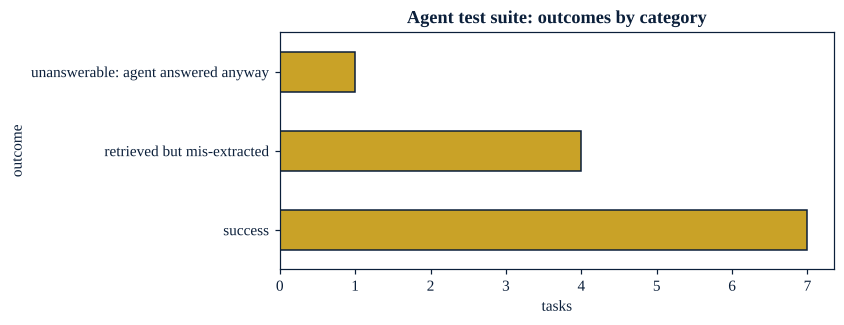

In [13]:
print("success rate:", round((R.outcome == "success").mean(), 3), "| mean steps:", round(R.steps.mean(), 2),
      "| total est. cost $:", round(R["est. cost $"].sum(), 4))
print("\nFailure taxonomy:\n" + R.outcome.value_counts().to_string())
print("\nHuman-in-the-loop:", send_email("director@example.com", "Weekly report"), "->", send_email("director@example.com", "Weekly report", approved_by_human=True))

ax = R.outcome.value_counts().plot.barh(figsize=(6.5, 2.8), color=GOLD, edgecolor=NAVY)
ax.set_title("Agent test suite: outcomes by category"); ax.set_xlabel("tasks")
plt.savefig(FIG/"s5_agent_outcomes.png", bbox_inches="tight"); plt.show()

**What to report for any agent:** task success rate on a fixed suite, steps and tool calls per task, latency,
cost per task, a failure taxonomy, and which actions needed human approval. In class, run the same harness on
**GAIA** validation tasks and trace every call with **Langfuse** or **LangSmith**.

> The unanswerable task exposes a real weakness of our simple policy: it always answers from the top passage.
> Add the abstention rule from Sunday 4 (coverage check) as a guardrail — that is your first improvement ticket.

---
<div style="background:#FFF3E0;border-left:6px solid #FF9933;padding:12px 16px;border-radius:6px">
<b>GitHub submission — by 18:00 local time today</b><br>
1. Copy this notebook into <code>P5-scholaragent/notebooks/</code> of your portfolio repo.<br>
2. Move reusable functions into <code>P5-scholaragent/src/</code>, save plots into <code>results/</code>.<br>
3. Update the project README (problem, dataset, method, results, how to run, limitations &amp; ethics, AI-assistant use).<br>
4. <code>git push origin main</code> → <code>git tag -a sunday-5 -m "Sunday 5 submission"</code> → <code>git push origin sunday-5</code><br>
5. Create a GitHub Release from the tag and submit the link on the AlgoProfessor form.
</div>